In [6]:
%pip install -q scikit-learn matplotlib seaborn pandas pillow python-docx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import os, json, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from PIL import Image

warnings.filterwarnings("ignore")

PROJECT_DIR = r"F:\ANALISIS BIG DATA S7\Klasifikasi Citra Emosi Wajah Menggunakan CNN"
DATA_DIR = os.path.join(PROJECT_DIR, "processed_data")
OUT_DIR  = os.path.join(PROJECT_DIR, "hasil")
os.makedirs(OUT_DIR, exist_ok=True)

IMG_SIZE = 48
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")

def save_json(obj, name):
    with open(os.path.join(OUT_DIR, name), "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)

def load_json(name):
    with open(os.path.join(OUT_DIR, name), encoding="utf-8") as f:
        return json.load(f)

class_names = sorted(d for d in os.listdir(DATA_DIR)
                     if os.path.isdir(os.path.join(DATA_DIR, d)))
NUM_CLASSES = len(class_names)
files_by_class = {c: [f for f in os.listdir(os.path.join(DATA_DIR, c))
                      if f.lower().endswith(IMG_EXT)] for c in class_names}
counts = {c: len(v) for c, v in files_by_class.items()}

df_count = pd.DataFrame({"Emosi": list(counts.keys()), "Jumlah": list(counts.values())})
df_count["Persen (%)"] = (df_count["Jumlah"] / df_count["Jumlah"].sum() * 100).round(2)

print("Jumlah kelas   :", NUM_CLASSES, "->", class_names)
print("Total gambar   :", int(df_count["Jumlah"].sum()))
print(df_count.to_string(index=False))
assert all(v > 0 for v in counts.values()), "Ada folder kelas yang kosong!"

Jumlah kelas   : 7 -> ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Total gambar   : 49779
   Emosi  Jumlah  Persen (%)
   angry    5920       11.89
 disgust    5920       11.89
    fear    5920       11.89
   happy   11398       22.90
 neutral    8166       16.40
     sad    6535       13.13
surprise    5920       11.89


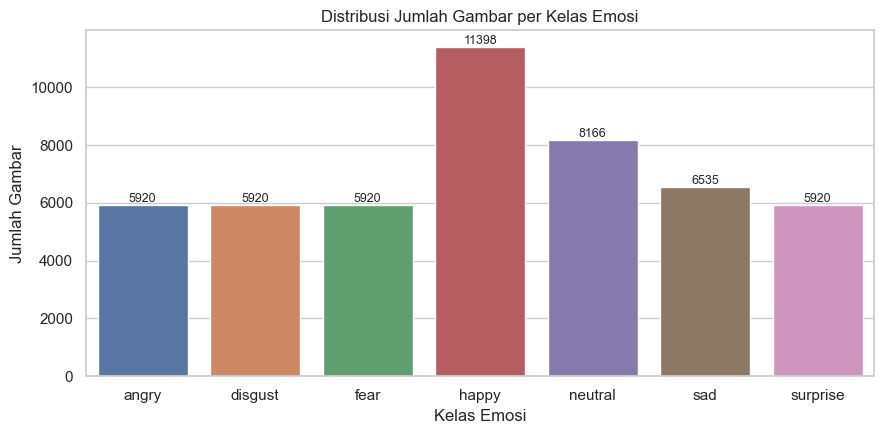

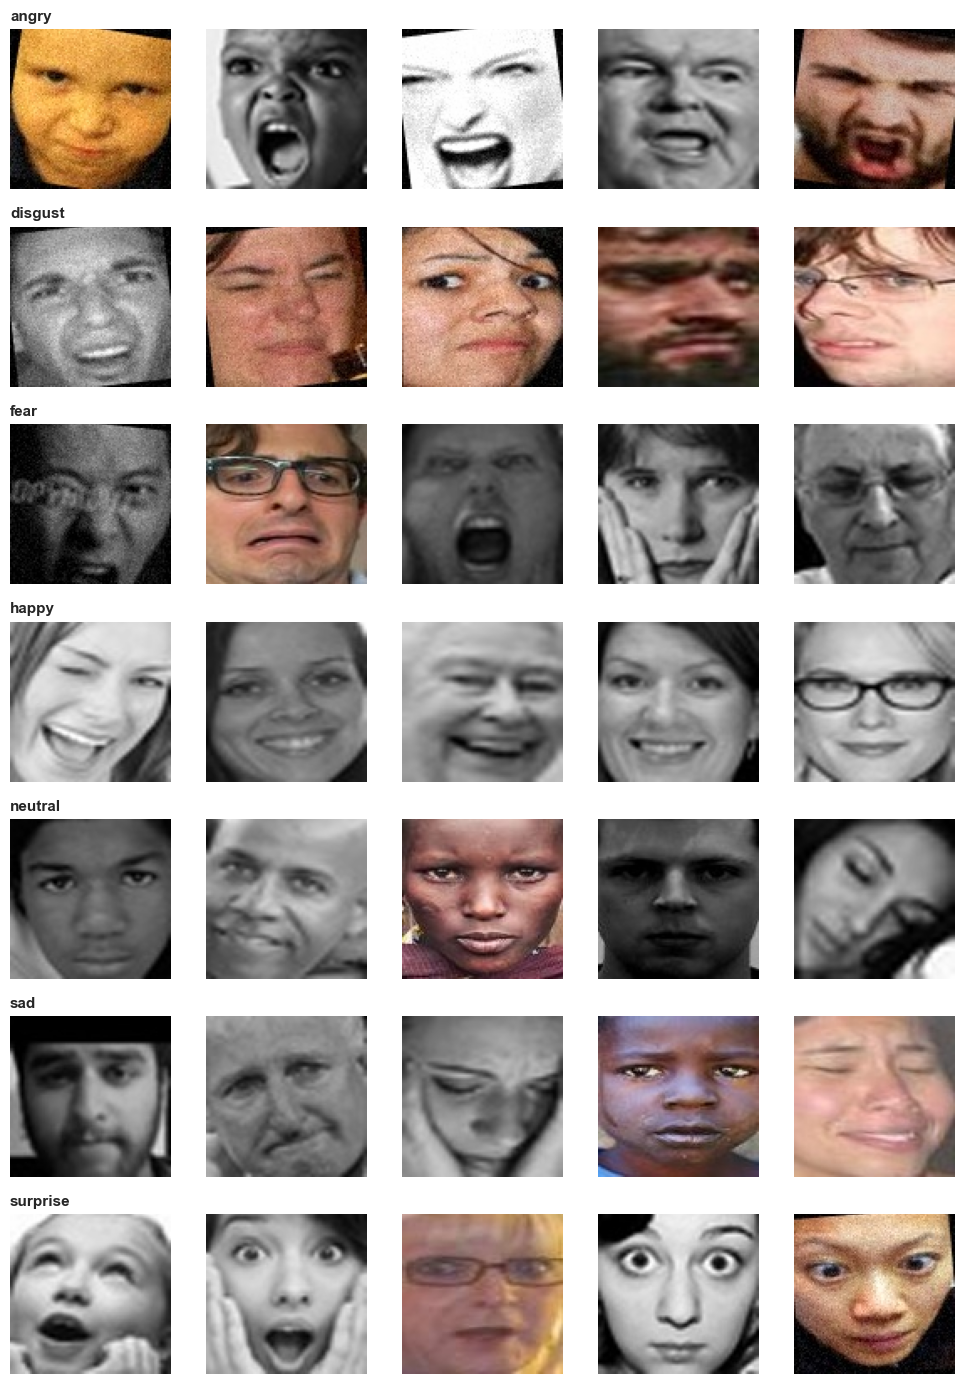

Ukuran gambar : {'96x96': 700}
Mode warna    : {'RGB': 700}
Format file   : {'.jpg': 700}

Statistik Kecerahan:
   Emosi  Rata-rata piksel  Std piksel
   angry             129.3        50.8
 disgust             128.9        51.7
    fear             137.2        52.8
   happy             126.7        46.7
 neutral             133.5        48.5
     sad             128.3        49.1
surprise             138.2        49.7

Kelas terbanyak  : happy (11398)
Kelas tersedikit : angry (5920)
Rasio imbalance  : 1.9x -> TIDAK seimbang

EDA BERHASIL DISELESAIKAN!
File tersimpan:
- eda_distribusi.png
- eda_contoh.png
- info_dataset.json


In [11]:

# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# Inisialisasi informasi dataset
info = {}

# Pastikan folder output tersedia
os.makedirs(OUT_DIR, exist_ok=True)


# ==========================================
# 1. DISTRIBUSI KELAS
# ==========================================

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.barplot(
    data=df_count,
    x="Emosi",
    y="Jumlah",
    hue="Emosi",
    legend=False,
    ax=ax
)

for cont in ax.containers:
    ax.bar_label(cont, fontsize=9)

ax.set_title("Distribusi Jumlah Gambar per Kelas Emosi")
ax.set_xlabel("Kelas Emosi")
ax.set_ylabel("Jumlah Gambar")

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "eda_distribusi.png"),
    dpi=150
)
plt.show()


# ==========================================
# 2. CONTOH GAMBAR TIAP KELAS
# ==========================================

n_show = 5

fig, axes = plt.subplots(
    NUM_CLASSES,
    n_show,
    figsize=(10, 2 * NUM_CLASSES),
    squeeze=False
)

for i, c in enumerate(class_names):

    pick = random.sample(
        files_by_class[c],
        min(n_show, len(files_by_class[c]))
    )

    for j in range(n_show):

        axes[i, j].axis("off")

        if j < len(pick):

            img_path = os.path.join(DATA_DIR, c, pick[j])

            with Image.open(img_path) as im:
                axes[i, j].imshow(im.copy(), cmap="gray")

        if j == 0:
            axes[i, j].set_title(
                c,
                loc="left",
                fontsize=11,
                fontweight="bold"
            )

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "eda_contoh.png"),
    dpi=150
)
plt.show()


# ==========================================
# 3. UKURAN, MODE WARNA, FORMAT, KECERAHAN
# ==========================================

sizes = Counter()
modes = Counter()
exts = Counter()
bright = []

for c in class_names:

    sample = random.sample(
        files_by_class[c],
        min(100, len(files_by_class[c]))
    )

    means = []
    stds = []

    for f in sample:

        img_path = os.path.join(DATA_DIR, c, f)

        with Image.open(img_path) as im:

            sizes[f"{im.size[0]}x{im.size[1]}"] += 1
            modes[im.mode] += 1
            exts[os.path.splitext(f)[1].lower()] += 1

            a = np.asarray(
                im.convert("L"),
                dtype="float32"
            )

            means.append(a.mean())
            stds.append(a.std())

    bright.append({
        "Emosi": c,
        "Rata-rata piksel": round(float(np.mean(means)), 1) if means else 0,
        "Std piksel": round(float(np.mean(stds)), 1) if stds else 0
    })


df_bright = pd.DataFrame(bright)

print("Ukuran gambar :", dict(sizes))
print("Mode warna    :", dict(modes))
print("Format file   :", dict(exts))

print("\nStatistik Kecerahan:")
print(df_bright.to_string(index=False))


# ==========================================
# 4. CLASS IMBALANCE
# ==========================================

kls_max = df_count.loc[df_count["Jumlah"].idxmax()]
kls_min = df_count.loc[df_count["Jumlah"].idxmin()]

rasio = float(
    kls_max["Jumlah"] / kls_min["Jumlah"]
) if kls_min["Jumlah"] > 0 else 0

print(f"\nKelas terbanyak  : {kls_max['Emosi']} ({int(kls_max['Jumlah'])})")
print(f"Kelas tersedikit : {kls_min['Emosi']} ({int(kls_min['Jumlah'])})")

print(
    f"Rasio imbalance  : {rasio:.1f}x ->",
    "TIDAK seimbang" if rasio > 1.5 else "relatif seimbang"
)


# ==========================================
# 5. SIMPAN INFORMASI DATASET KE JSON
# ==========================================

info.update({

    "ukuran": dict(sizes),

    "mode_warna": dict(modes),

    "format": dict(exts),

    "kecerahan": bright,

    "kelas_terbanyak": [
        str(kls_max["Emosi"]),
        int(kls_max["Jumlah"])
    ],

    "kelas_tersedikit": [
        str(kls_min["Emosi"]),
        int(kls_min["Jumlah"])
    ],

    "rasio_imbalance": round(rasio, 2)

})

save_json(info, "info_dataset.json")

print("\n================================")
print("EDA BERHASIL DISELESAIKAN!")
print("================================")
print("File tersimpan:")
print("- eda_distribusi.png")
print("- eda_contoh.png")
print("- info_dataset.json")


In [12]:
X, y, rusak = [], [], 0
for idx, c in enumerate(class_names):
    for f in files_by_class[c]:
        try:
            im = Image.open(os.path.join(DATA_DIR, c, f)).convert("L")       # grayscale
            im = im.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)              # resize seragam
            X.append(np.asarray(im, dtype="float32") / 255.0)                # normalisasi 0-1
            y.append(idx)
        except Exception as e:
            rusak += 1
            print("Dilewati:", f, "|", e)

X = np.array(X, dtype="float32").reshape(-1, IMG_SIZE, IMG_SIZE, 1)
y = np.array(y)
print(f"X: {X.shape} | rentang piksel: {X.min():.2f}-{X.max():.2f} | file rusak: {rusak}")

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 80% latih (10% darinya jadi validasi) dan 20% uji
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.10, stratify=y_trainval, random_state=SEED)

# One-hot encoding
y_train_oh = np.eye(NUM_CLASSES, dtype="float32")[y_train]
y_val_oh   = np.eye(NUM_CLASSES, dtype="float32")[y_val]
y_test_oh  = np.eye(NUM_CLASSES, dtype="float32")[y_test]

# Class weight untuk imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}

df_split = pd.DataFrame({
    "Emosi": class_names,
    "Latih": np.bincount(y_train, minlength=NUM_CLASSES),
    "Validasi": np.bincount(y_val, minlength=NUM_CLASSES),
    "Uji": np.bincount(y_test, minlength=NUM_CLASSES),
    "Class weight": [round(class_weight[i], 3) for i in range(NUM_CLASSES)],
})
print(f"\nLatih: {len(X_train)} | Validasi: {len(X_val)} | Uji: {len(X_test)}")
print(df_split.to_string(index=False))

info.update({
    "n_train": int(len(X_train)), "n_val": int(len(X_val)), "n_test": int(len(X_test)),
    "n_rusak": rusak, "split": df_split.to_dict(orient="records"),
    "class_weight": {class_names[i]: round(w, 4) for i, w in class_weight.items()},
})
save_json(info, "info_dataset.json")

X: (49779, 48, 48, 1) | rentang piksel: 0.00-1.00 | file rusak: 0

Latih: 35840 | Validasi: 3983 | Uji: 9956
   Emosi  Latih  Validasi  Uji  Class weight
   angry   4262       474 1184         1.201
 disgust   4263       473 1184         1.201
    fear   4262       474 1184         1.201
   happy   8206       912 2280         0.624
 neutral   5880       653 1633         0.871
     sad   4705       523 1307         1.088
surprise   4262       474 1184         1.201


In [19]:
info = load_json("info_dataset.json")
info.update({
    "sumber": "https://www.kaggle.com/datasets/fahadullaha/facial-emotion-recognition-dataset/data",
    "class_names": class_names,
    "counts": counts,
    "total": int(sum(counts.values())),
    "img_size": IMG_SIZE,
})
save_json(info, "info_dataset.json")
print("OK:", info["class_names"], info["total"])

OK: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise'] 49779


In [ ]:
X, y, rusak = [], [], 0
for idx, c in enumerate(class_names):
    for f in files_by_class[c]:
        try:
            im = Image.open(os.path.join(DATA_DIR, c, f)).convert("L")       # grayscale
            im = im.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)              # resize seragam
            X.append(np.asarray(im, dtype="float32") / 255.0)                # normalisasi 0-1
            y.append(idx)
        except Exception as e:
            rusak += 1
            print("Dilewati:", f, "|", e)

X = np.array(X, dtype="float32").reshape(-1, IMG_SIZE, IMG_SIZE, 1)
y = np.array(y)
print(f"X: {X.shape} | rentang piksel: {X.min():.2f}-{X.max():.2f} | file rusak: {rusak}")

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 80% latih (10% darinya jadi validasi) dan 20% uji
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.10, stratify=y_trainval, random_state=SEED)

# One-hot encoding
y_train_oh = np.eye(NUM_CLASSES, dtype="float32")[y_train]
y_val_oh   = np.eye(NUM_CLASSES, dtype="float32")[y_val]
y_test_oh  = np.eye(NUM_CLASSES, dtype="float32")[y_test]

# Class weight untuk imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}

df_split = pd.DataFrame({
    "Emosi": class_names,
    "Latih": np.bincount(y_train, minlength=NUM_CLASSES),
    "Validasi": np.bincount(y_val, minlength=NUM_CLASSES),
    "Uji": np.bincount(y_test, minlength=NUM_CLASSES),
    "Class weight": [round(class_weight[i], 3) for i in range(NUM_CLASSES)],
})
print(f"\nLatih: {len(X_train)} | Validasi: {len(X_val)} | Uji: {len(X_test)}")
print(df_split.to_string(index=False))

info.update({
    "n_train": int(len(X_train)), "n_val": int(len(X_val)), "n_test": int(len(X_test)),
    "n_rusak": rusak, "split": df_split.to_dict(orient="records"),
    "class_weight": {class_names[i]: round(w, 4) for i, w in class_weight.items()},
})
save_json(info, "info_dataset.json")

X: (49779, 48, 48, 1) | rentang piksel: 0.00-1.00 | file rusak: 0

Latih: 35840 | Validasi: 3983 | Uji: 9956
   Emosi  Latih  Validasi  Uji  Class weight
   angry   4262       474 1184         1.201
 disgust   4263       473 1184         1.201
    fear   4262       474 1184         1.201
   happy   8206       912 2280         0.624
 neutral   5880       653 1633         0.871
     sad   4705       523 1307         1.088
surprise   4262       474 1184         1.201


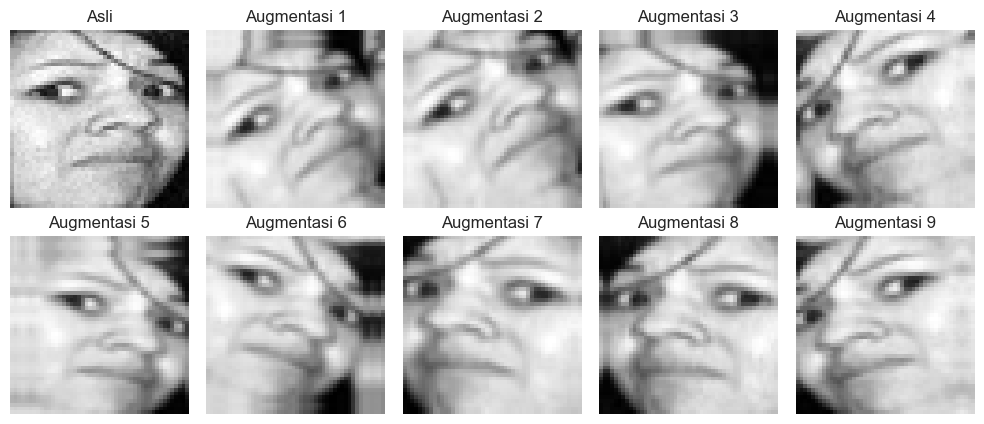

Model: "CNN_Emosi_Wajah"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_citra (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 48, 48, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 48, 48, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_2 (Activation)            │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 24, 24, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 24, 24, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_2 (Activation)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 12, 12, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 12, 12, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_2 (BatchNormalization)      │ (None, 12, 12, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_2 (Activation)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 6, 6, 128)      │             

 Total params: 1,470,247 (5.61 MB)

 Trainable params: 1,468,839 (5.60 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)

EPOCHS = 50
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
LAST_CONV = "relu3_2"          # layer untuk Grad-CAM

# Augmentasi (hanya aktif saat training)
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.08, 0.08),
], name="augmentasi")

# Pratinjau augmentasi
sample = X_train[:1]
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
axes[0, 0].imshow(sample[0, :, :, 0], cmap="gray"); axes[0, 0].set_title("Asli")
for k, ax in enumerate(axes.flat[1:], start=1):
    ax.imshow(augment(sample, training=True)[0, :, :, 0], cmap="gray"); ax.set_title(f"Augmentasi {k}")
for ax in axes.flat: ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "augmentasi_contoh.png"), dpi=150)
plt.show()

def conv_block(x, filters, block, dropout):
    for i in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv{block}_{i}")(x)
        x = layers.BatchNormalization(name=f"bn{block}_{i}")(x)
        x = layers.Activation("relu", name=f"relu{block}_{i}")(x)
    x = layers.MaxPooling2D(2, name=f"pool{block}")(x)
    x = layers.Dropout(dropout, name=f"drop{block}")(x)
    return x

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="input_citra")
x = augment(inputs)
x = conv_block(x, 32, 1, 0.25)
x = conv_block(x, 64, 2, 0.25)
x = conv_block(x, 128, 3, 0.30)
x = layers.Flatten(name="flatten")(x)
x = layers.Dense(256, use_bias=False, name="fc1")(x)
x = layers.BatchNormalization(name="bn_fc1")(x)
x = layers.Activation("relu", name="relu_fc1")(x)
x = layers.Dropout(0.5, name="drop_fc1")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="output")(x)

model = keras.Model(inputs, outputs, name="CNN_Emosi_Wajah")
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

In [15]:
MODEL_PATH = os.path.join(OUT_DIR, "model_emosi_cnn.keras")
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

t0 = time.time()
history = model.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    class_weight=class_weight, callbacks=callbacks, verbose=1,
)
durasi_menit = (time.time() - t0) / 60

hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
save_json(hist, "history.json")
model.save(MODEL_PATH)

layer_rows = []
for l in model.layers:
    try:
        shp = str(tuple(l.output.shape))
    except Exception:
        shp = "-"
    layer_rows.append({"layer": l.name, "tipe": l.__class__.__name__,
                       "output": shp, "param": int(l.count_params())})

save_json({
    "epochs_maks": EPOCHS, "epochs_dilatih": len(hist["loss"]),
    "best_epoch": int(np.argmin(hist["val_loss"]) + 1),
    "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "optimizer": "Adam", "loss": "categorical_crossentropy",
    "total_param": int(model.count_params()), "durasi_menit": round(durasi_menit, 1),
    "layers": layer_rows, "last_conv": LAST_CONV,
}, "train_info.json")
print(f"Selesai. Epoch dilatih: {len(hist['loss'])} | Durasi: {durasi_menit:.1f} menit")

Epoch 1/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 310s 544ms/step - accuracy: 0.2622 - loss: 1.9540 - val_accuracy: 0.4328 - val_loss: 1.5092 - learning_rate: 0.0010
Epoch 2/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 308s 549ms/step - accuracy: 0.4015 - loss: 1.5986 - val_accuracy: 0.4783 - val_loss: 1.3936 - learning_rate: 0.0010
Epoch 3/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 315s 562ms/step - accuracy: 0.4627 - loss: 1.4534 - val_accuracy: 0.4928 - val_loss: 1.3249 - learning_rate: 0.0010
Epoch 4/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 300s 536ms/step - accuracy: 0.5004 - loss: 1.3712 - val_accuracy: 0.5443 - val_loss: 1.2129 - learning_rate: 0.0010
Epoch 5/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 274s 489ms/step - accuracy: 0.5251 - loss: 1.3112 - val_accuracy: 0.5523 - val_loss: 1.2036 - learning_rate: 0.0010
Epoch 6/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 262s 467ms/step - accuracy: 0.5404 - loss: 1.2728 - val_accuracy: 0.4529 - val_loss: 1.5593 - learning_rate: 0.0010
Epoch 7/50
560/560 ━━━━━━━━━━━━━━━━━━━━ 266s 476ms/step - accura

In [16]:
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             classification_report, confusion_matrix)

test_loss, _ = model.evaluate(X_test, y_test_oh, verbose=0)
y_prob = model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

acc = accuracy_score(y_test, y_pred)
p_mac, r_mac, f_mac, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
p_wei, r_wei, f_wei, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

rep = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
df_rep = pd.DataFrame({
    "Precision": [rep[c]["precision"] for c in class_names],
    "Recall":    [rep[c]["recall"] for c in class_names],
    "F1-score":  [rep[c]["f1-score"] for c in class_names],
    "Support":   [int(rep[c]["support"]) for c in class_names],
}, index=class_names)

print(f"Test loss : {test_loss:.4f}")
print(f"Accuracy  : {acc:.4f}")
print(f"Macro     : P={p_mac:.4f}  R={r_mac:.4f}  F1={f_mac:.4f}")
print(f"Weighted  : P={p_wei:.4f}  R={r_wei:.4f}  F1={f_wei:.4f}\n")
print(df_rep.round(4).to_string())

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
np.save(os.path.join(OUT_DIR, "confusion_matrix.npy"), cm)

save_json({
    "accuracy": float(acc), "test_loss": float(test_loss),
    "macro": {"precision": float(p_mac), "recall": float(r_mac), "f1": float(f_mac)},
    "weighted": {"precision": float(p_wei), "recall": float(r_wei), "f1": float(f_wei)},
    "per_class": {c: {"precision": float(df_rep.loc[c, "Precision"]), "recall": float(df_rep.loc[c, "Recall"]),
                      "f1": float(df_rep.loc[c, "F1-score"]), "support": int(df_rep.loc[c, "Support"])}
                  for c in class_names},
}, "metrics.json")

# Interpretasi otomatis
terbaik, tersulit = df_rep["F1-score"].idxmax(), df_rep["F1-score"].idxmin()
cm_norm_ = cm / cm.sum(axis=1, keepdims=True)
off = cm_norm_.copy(); np.fill_diagonal(off, 0)
tertukar = class_names[int(off[class_names.index(tersulit)].argmax())]
print(f"\nKelas paling mudah : {terbaik} (F1 = {df_rep.loc[terbaik, 'F1-score']:.3f})")
print(f"Kelas paling sulit : {tersulit} (F1 = {df_rep.loc[tersulit, 'F1-score']:.3f}), "
      f"paling sering tertukar dengan '{tertukar}'")

Test loss : 1.1383
Accuracy  : 0.5766
Macro     : P=0.5650  R=0.5542  F1=0.5340
Weighted  : P=0.5896  R=0.5766  F1=0.5614

          Precision  Recall  F1-score  Support
angry        0.4683  0.4426    0.4551     1184
disgust      0.5552  0.7221    0.6278     1184
fear         0.5551  0.1106    0.1845     1184
happy        0.8283  0.7447    0.7843     2280
neutral      0.5133  0.5891    0.5486     1633
sad          0.3997  0.5471    0.4619     1307
surprise     0.6350  0.7230    0.6761     1184

Kelas paling mudah : happy (F1 = 0.784)
Kelas paling sulit : fear (F1 = 0.185), paling sering tertukar dengan 'surprise'


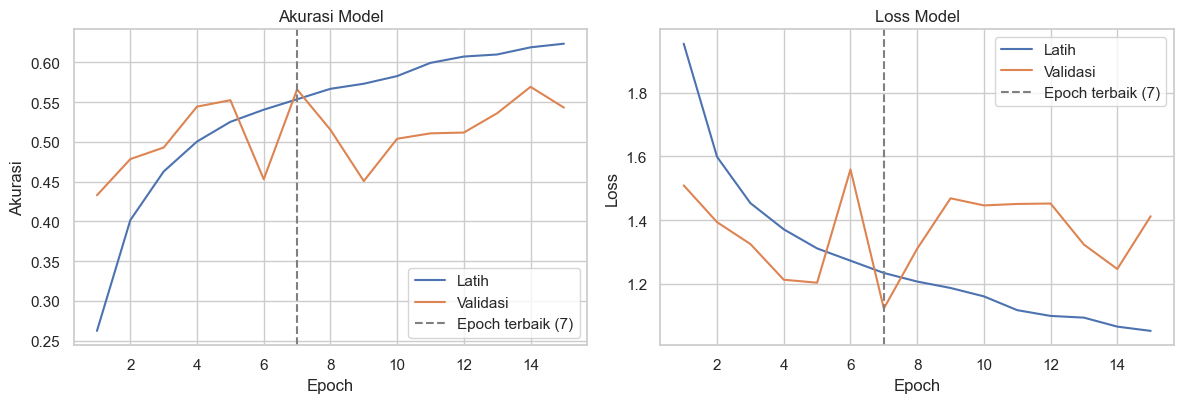

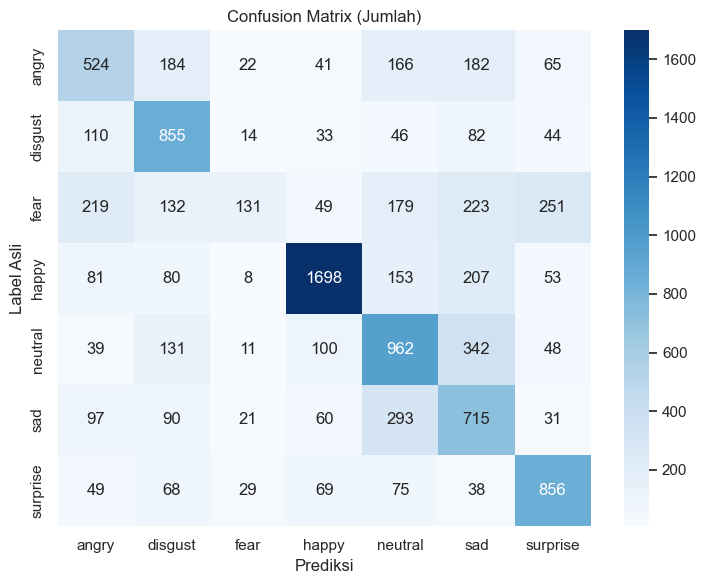

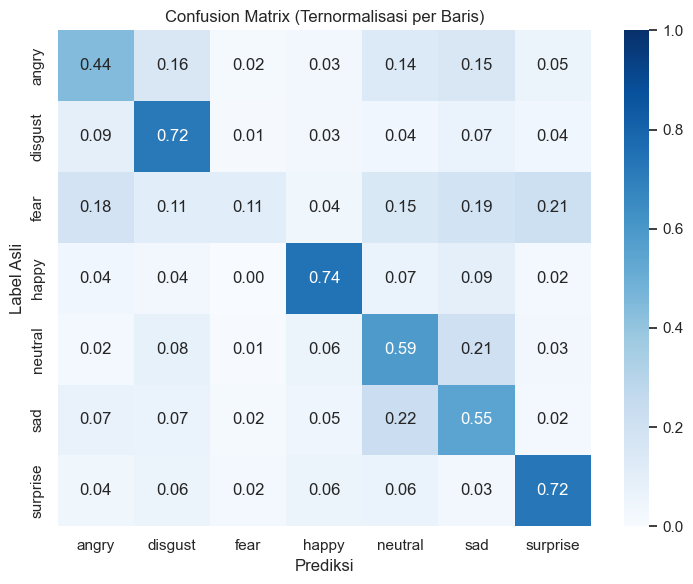

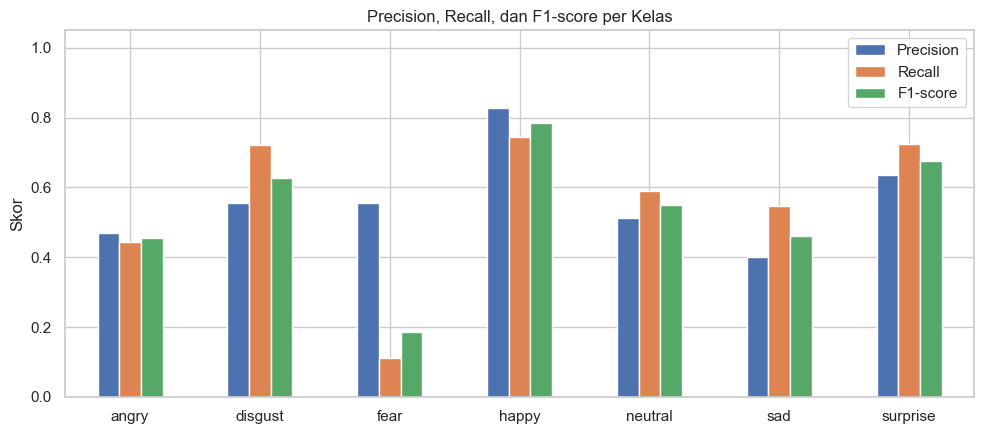

In [17]:
ep = range(1, len(hist["loss"]) + 1)
best_ep = int(np.argmin(hist["val_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(ep, hist["accuracy"], label="Latih"); axes[0].plot(ep, hist["val_accuracy"], label="Validasi")
axes[0].axvline(best_ep, ls="--", c="gray", label=f"Epoch terbaik ({best_ep})")
axes[0].set(title="Akurasi Model", xlabel="Epoch", ylabel="Akurasi"); axes[0].legend()
axes[1].plot(ep, hist["loss"], label="Latih"); axes[1].plot(ep, hist["val_loss"], label="Validasi")
axes[1].axvline(best_ep, ls="--", c="gray", label=f"Epoch terbaik ({best_ep})")
axes[1].set(title="Loss Model", xlabel="Epoch", ylabel="Loss"); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "kurva_akurasi_loss.png"), dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set(title="Confusion Matrix (Jumlah)", xlabel="Prediksi", ylabel="Label Asli")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm_norm_, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set(title="Confusion Matrix (Ternormalisasi per Baris)", xlabel="Prediksi", ylabel="Label Asli")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix_norm.png"), dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
df_rep[["Precision", "Recall", "F1-score"]].plot(kind="bar", ax=ax, rot=0)
ax.set(title="Precision, Recall, dan F1-score per Kelas", ylim=(0, 1.05), ylabel="Skor")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "metrik_per_kelas.png"), dpi=150); plt.show()

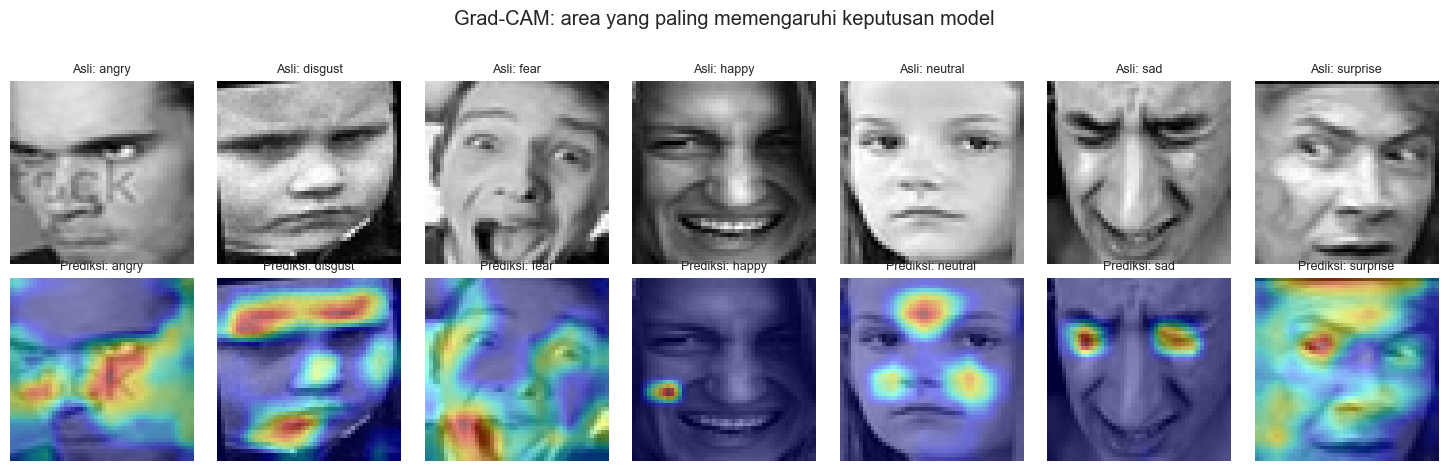

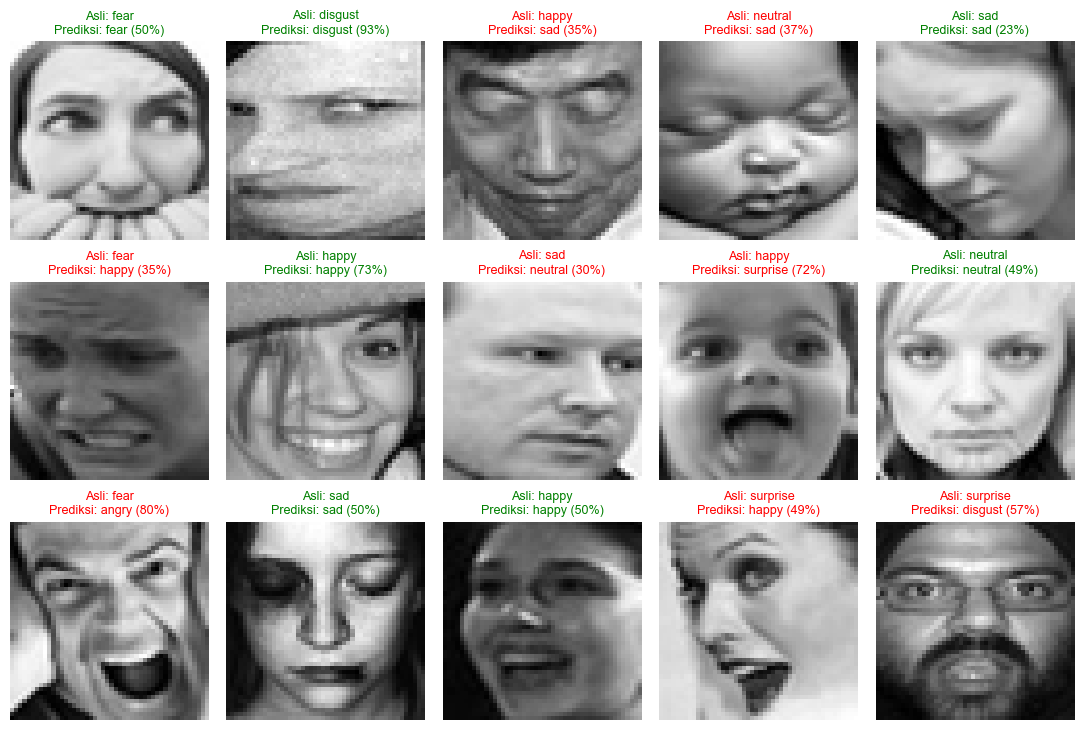

In [18]:
def make_gradcam(img, model, last_conv=LAST_CONV):
    grad_model = keras.Model(model.inputs, [model.get_layer(last_conv).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img[None, ...], training=False)
        idx = int(tf.argmax(preds[0]))
        score = preds[:, idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
    return cam, idx, preds.numpy()[0]

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2.1 * NUM_CLASSES, 4.6))
for c_idx, c in enumerate(class_names):
    cand = np.where(y_test == c_idx)[0]
    benar = cand[y_pred[cand] == c_idx]
    i = int((benar if len(benar) else cand)[0])
    cam, pidx, _ = make_gradcam(X_test[i], model)
    axes[0, c_idx].imshow(X_test[i, :, :, 0], cmap="gray")
    axes[0, c_idx].set_title(f"Asli: {c}", fontsize=9)
    axes[1, c_idx].imshow(X_test[i, :, :, 0], cmap="gray")
    axes[1, c_idx].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, c_idx].set_title(f"Prediksi: {class_names[pidx]}", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Grad-CAM: area yang paling memengaruhi keputusan model", y=1.02)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gradcam.png"), dpi=150, bbox_inches="tight"); plt.show()

rng = np.random.RandomState(SEED)
pick = rng.choice(len(X_test), size=min(15, len(X_test)), replace=False)
fig, axes = plt.subplots(3, 5, figsize=(11, 7.5))
for ax, i in zip(axes.flat, pick):
    ok = y_pred[i] == y_test[i]
    ax.imshow(X_test[i, :, :, 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"Asli: {class_names[y_test[i]]}\nPrediksi: {class_names[y_pred[i]]} ({y_prob[i].max()*100:.0f}%)",
                 fontsize=9, color="green" if ok else "red")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "contoh_prediksi.png"), dpi=150); plt.show()

In [20]:
info = {
    "sumber": "https://www.kaggle.com/datasets/fahadullaha/facial-emotion-recognition-dataset/data",
    "class_names": class_names, "counts": counts,
    "total": int(sum(counts.values())), "img_size": IMG_SIZE,
}